# Задание 2.5*

Пусть $A$ и $C$ — действительные, а $B$ — комплексная постоянные, и пусть $AC<|B|^2$. Покажите, что уравнение

$$
A|z|^2+\overline{B}z+B\overline{z}+C=0,\qquad (A>0),
$$

является уравнением окружности, а также найдите центр этой окружности и её радиус.

## Теория

Окружность с центром $z_0$ и радиусом $R$ — это множество $|z-z_0|=R$. Так как $|w|^2=w\overline{w}$, её уравнение можно записать в виде

$$
|z-z_0|^2=(z-z_0)(\overline{z}-\overline{z_0})=|z|^2-\overline{z_0}\,z-z_0\,\overline{z}+|z_0|^2=R^2 .
$$

**Доказательство (выделение полного квадрата).** Разделим исходное уравнение на $A>0$:

$$
|z|^2+\frac{\overline{B}}{A}z+\frac{B}{A}\overline{z}+\frac{C}{A}=0 .
$$

Сравнивая с предыдущей формулой, берём $z_0=-\dfrac{B}{A}$ (тогда $-\overline{z_0}=\dfrac{\overline B}{A}$, так как $A$ действительно) и добавляем и вычитаем $|z_0|^2=\dfrac{|B|^2}{A^2}$:

$$
\left|z+\frac{B}{A}\right|^2=\frac{|B|^2}{A^2}-\frac{C}{A}=\frac{|B|^2-AC}{A^2}.
$$

По условию $AC<|B|^2$, поэтому правая часть **положительна**, и уравнение задаёт окружность

$$
\boxed{\;z_0=-\frac{B}{A},\qquad R=\frac{\sqrt{|B|^2-AC}}{A}\;}
$$

(при $AC=|B|^2$ получилась бы одна точка, при $AC>|B|^2$ — пустое множество).

**В координатах:** при $z=x+iy$, $B=b_1+ib_2$ имеем $\overline{B}z+B\overline{z}=2\operatorname{Re}(\overline{B}z)=2(b_1x+b_2y)$, то есть уравнение $A(x^2+y^2)+2b_1x+2b_2y+C=0$ — общее уравнение окружности.

В коде: 1) проверяем тождество символьно в `sympy`; 2) на числовом примере сравниваем линию уровня левой части с окружностью, построенной по найденным формулам.

Левая часть в координатах: A*x**2 + A*y**2 + C + 2*b1*x + 2*b2*y
Центр z0 = (-b1 - I*b2)/A ,  R² = (-A*C + b1**2 + b2**2)/A**2
lhs - A(|z - z0|² - R²) = 0

Пример: A = 1, B = -2 - i, C = 1  ->  центр z0 = 2 + 1i, радиус R = 2


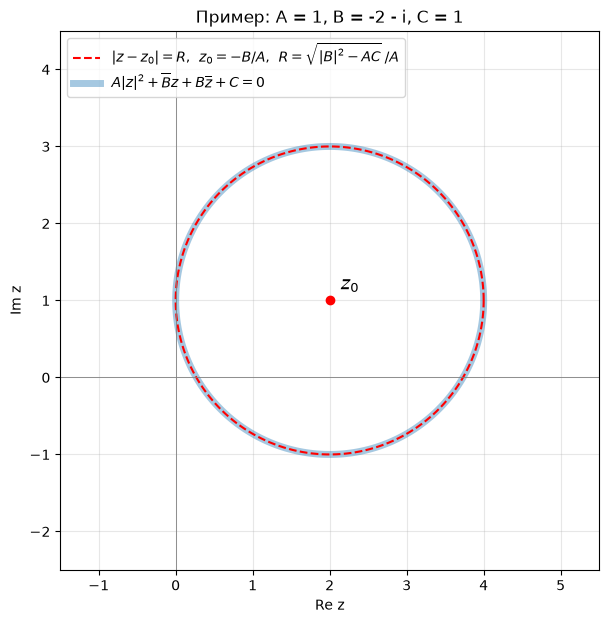

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

# ---------- 1. Символьная проверка ----------
x, y, b1, b2, C = sp.symbols('x y b1 b2 C', real=True)
A = sp.symbols('A', positive=True)
z = x + sp.I*y          # z = x + iy
B = b1 + sp.I*b2        # B = b1 + i·b2

# Левая часть уравнения в координатах (x, y)
lhs = sp.expand(A*sp.Abs(z)**2 + sp.conjugate(B)*z + B*sp.conjugate(z) + C)
print("Левая часть в координатах:", lhs)

# Найденные в теории центр и квадрат радиуса
z0 = -B/A
R2 = (sp.Abs(B)**2 - A*C)/A**2
print("Центр z0 =", z0, ",  R² =", sp.factor(R2))

# Левая часть должна тождественно совпасть с A·(|z - z0|² - R²)
circle = A*((x - sp.re(z0))**2 + (y - sp.im(z0))**2 - R2)
print("lhs - A(|z - z0|² - R²) =", sp.simplify(lhs - circle))

# ---------- 2. Числовой пример ----------
A_, B_, C_ = 1, -2 - 1j, 1                  # AC = 1 < |B|² = 5
z0_ = -B_/A_                                # центр
R_ = np.sqrt(abs(B_)**2 - A_*C_)/A_         # радиус
example = "A = 1, B = -2 - i, C = 1"
print(f"\nПример: {example}  ->  центр z0 = {z0_.real:g} + {z0_.imag:g}i, радиус R = {R_:g}")

# Левая часть уравнения на сетке точек плоскости (она действительна)
X, Y = np.meshgrid(np.linspace(-1.5, 5.5, 600), np.linspace(-2.5, 4.5, 600))
Z = X + 1j*Y
F = (A_*np.abs(Z)**2 + np.conj(B_)*Z + B_*np.conj(Z) + C_).real

fig, ax = plt.subplots(figsize=(7, 7))
# Множество решений уравнения — нулевая линия уровня левой части
ax.contour(X, Y, F, levels=[0], colors='tab:blue', linewidths=5, alpha=0.4)
# Окружность по найденным формулам — должна лечь точно поверх
t = np.linspace(0, 2*np.pi, 400)
ax.plot(z0_.real + R_*np.cos(t), z0_.imag + R_*np.sin(t), 'r--', lw=1.5,
        label=r"$|z-z_0|=R$,  $z_0=-B/A$,  $R=\sqrt{|B|^2-AC}\,/A$")
ax.plot([], [], color='tab:blue', lw=5, alpha=0.4, label=r"$A|z|^2+\overline{B}z+B\overline{z}+C=0$")
ax.plot(z0_.real, z0_.imag, 'ro')
ax.annotate("$z_0$", (z0_.real, z0_.imag), textcoords="offset points", xytext=(8, 8), fontsize=13)

ax.axhline(0, color='gray', lw=0.6)
ax.axvline(0, color='gray', lw=0.6)
ax.set_aspect('equal')
ax.grid(alpha=0.3)
ax.set_xlabel("Re z")
ax.set_ylabel("Im z")
ax.set_title(f"Пример: {example}")
ax.legend(loc="upper left", fontsize=10)
plt.show()